## A rule as weights

A trend rule written as an array: for every hour of Binance's BTCUSDT in 2024 and 2025, the
share of the account to hold. `probatum.backtest` runs the whole array in one call into
Rust, settling each bar's fills, costs and barriers before it reads the next.

In [1]:
import pathlib

import exchange_router
import matplotlib.pyplot
import matplotlib.ticker
import numpy
import pandas
import probatum

matplotlib.pyplot.style.use(style="../oceano.mplstyle")

print(f"probatum {probatum.__version__}, exchange-router {exchange_router.__version__}")

probatum 4.0.0, exchange-router 4.0.0


### The bars

Fetched once through the router and saved in `bars/`, from where later runs load them,
checked against the fingerprint they were saved under.

In [2]:
PATH = pathlib.Path("../bars/binance-spot-btcusdt-1h-2024-2025")

if PATH.exists():
    data = probatum.Data.load(path=PATH)
else:
    with exchange_router.Router.local(exchanges=["binance"]) as router:
        data = probatum.Data.from_router(router, exchange="binance", market="spot",
                                         interval="1h", symbols=["BTCUSDT"],
                                         start="2024-01-01", end="2025-12-31")
    data.save(path=PATH)

data

Data(BTCUSDT, 1h, 17544 bars from 2024-01-01 00:00 to 2025-12-31 23:00)

### The rule

The whole account in the pair while its close is above the average of the last 200 closes,
and none of it below. Row `t` is the decision at the close of bar `t`, which fills at the
next bar's open.

In [3]:
close   = data.close
average = probatum.ta.sma(close, length=200)

weights = numpy.where(close > average, 1.0, 0.0)

### A run

`binance_spot` is the preset with Binance's spot instruments and fees. Each fill pays the
fee, and a market order also half the spread estimated from the last 24 bars, the slippage
and the impact. A Result shows as its summary, each statistic beside buying and holding the
same bars, with its interval.

In [4]:
result = probatum.backtest(weights, data=data, venue="binance_spot")

result

,run,buy_and_hold,low,high,level,method,why_none
total_return_pct,-25.91,106.12,,,,,1
cagr_pct,-13.91,43.50,,,,,1
volatility_pct,33.13,48.68,,,,,1
sharpe,-0.29,0.99,-1.67,1.10,0.95,"delta method, Newey-West lag 3, floored at lag zero",
max_drawdown_pct,55.33,34.76,,,,,1
exposure_pct,52.84,,,,,,
num_trades,300,,,,,,
win_rate,0.14,,0.10,0.17,0.95,percentile bootstrap of round trips,
profit_factor,0.90,,0.53,1.60,0.95,BCa bootstrap of round trips,
costs,"7,575",,,,,,


### What trading cost

Each kind of cost, totalled in USDT, the asset the account is kept in.

In [5]:
pandas.DataFrame({"USDT": result.costs}).round(decimals=2)

,USDT
fees,6840.42
funding,0.00
spread,32.81
slippage,665.89
impact,36.06
liquidation,0.00
dust,0.00


### Sized by volatility

A weight can be any share of the account. This one holds less of the pair as its last
week's moves grow, aiming at 40% a year, and `tolerance` skips a rebalance smaller than 5%
of the account, which would otherwise trade nearly every hour.

In [6]:
returns    = numpy.log(close / probatum.ta.shift(close))
volatility = probatum.ta.stdev(returns, length=24 * 7) * numpy.sqrt(24 * 365)

sized = numpy.where(close > average, numpy.minimum(1.0, 0.4 / volatility), 0.0)

every    = probatum.backtest(sized, data=data, venue="binance_spot")
tolerant = probatum.backtest(sized, data=data, venue="binance_spot", tolerance=0.05)

print(f"fills with no tolerance   {len(every.fills):>6,}")
print(f"fills with a 5% one       {len(tolerant.fills):>6,}")

fills with no tolerance    4,421
fills with a 5% one          729


### A stop and a take-profit

An array run also takes a stop and a take-profit for each round trip, as returns from its
average entry. A barrier that fills holds the pair flat until the rule asks for none of it,
and then for it again.

In [7]:
guarded = probatum.backtest(sized, data=data, venue="binance_spot", tolerance=0.05,
                            stop=0.04, take_profit=0.12)

statistics = ["total_return_pct", "sharpe", "max_drawdown_pct", "volatility_pct",
              "exposure_pct", "num_trades", "num_fills"]

runs = probatum.compare({"crossing": result, "sized": tolerant, "sized, barriers": guarded},
                        keys=statistics)
runs.to_pandas().set_index(keys="name")[statistics].round(decimals=2)

,total_return_pct,sharpe,max_drawdown_pct,volatility_pct,exposure_pct,num_trades,num_fills
name,,,,,,,
crossing,-25.91,-0.29,55.33,33.13,52.84,300,600
sized,-23.07,-0.35,48.22,26.97,52.84,300,729
"sized, barriers",-28.37,-0.57,42.75,24.06,43.07,300,695


### The chart

The first run over its candles with the average it decided on, opened on its last 60 days.
An arrow marks each round trip's entry and exit on the bars they filled on, and the equity
runs under the price, its fall from each peak shaded.

In [8]:
result.chart(probatum.chart.marks.Line(average, name="SMA 200"), focus=24 * 60,
             title="BTCUSDT 1h at binance_spot, held above its 200-hour average")

Chart(bars=17544, panels=3)

### Equity beside its baselines

Every Result carries baselines on its own bars and venue: the opening cash, buying and
holding, and the same policy with the costs of trading taken out.

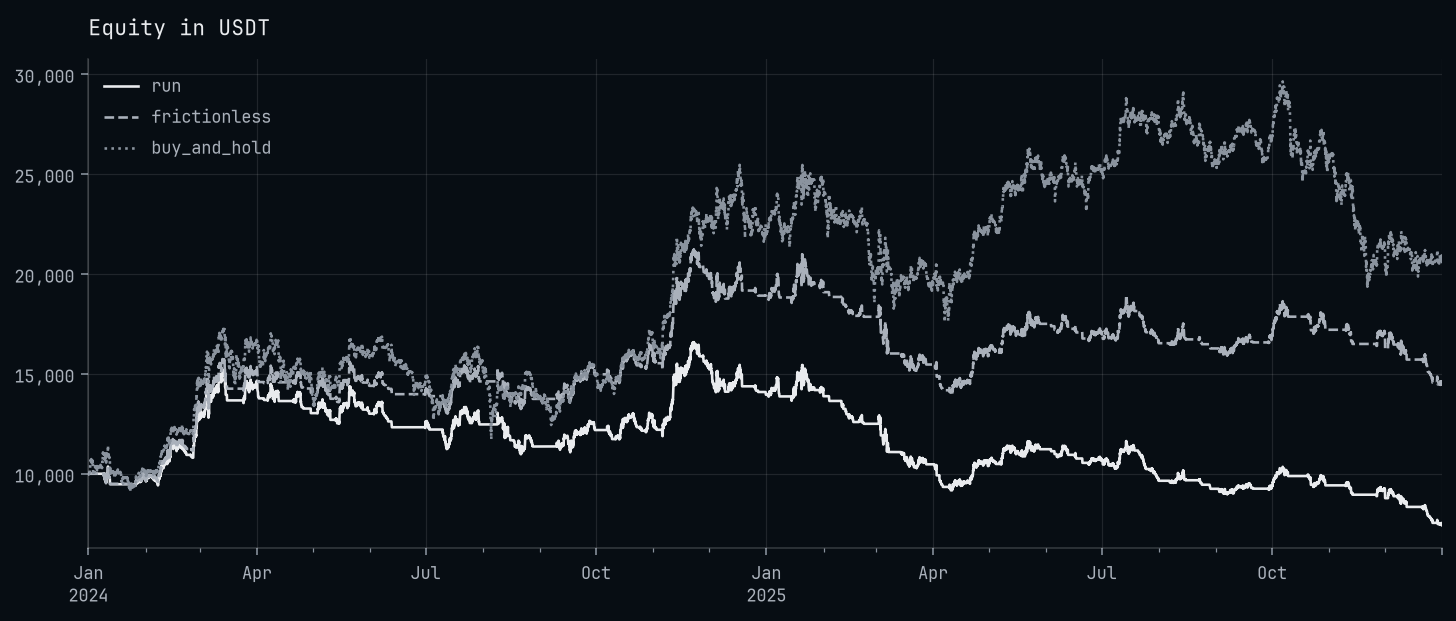

In [9]:
equity = result.baselines.to_pandas().set_index(keys="time")
equity["run"] = result.equity

axes = equity[["run", "frictionless", "buy_and_hold"]].plot(title="Equity in USDT", xlabel="")
axes.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter(fmt="{x:,.0f}"))
matplotlib.pyplot.show()